# <center> Customer Booking Prediction </center>

This notebook focuses on feature selection for a customer booking prediction problem. The goal is to reduce the number of input features while keeping the most informative variables for model training.

Workflow:
1. Load and inspect the dataset
2. Separate numerical and categorical features
3. Apply feature selection methods
4. Compare shortlisted features
5. Save the reduced dataset for modeling

## <center> Feature Selection </center>

This section identifies the variables that contribute the most to predicting whether a customer completes a booking. We reduce noisy, redundant, or weak features to improve model performance and interpretability.

The dataset contains many columns, so it is useful to remove less informative ones before building a model.

This notebook applies filter-based feature selection methods:

- Numerical features:
  - Pearson correlation / ANOVA F-score
  - Spearman rank correlation
  - Mutual information
- Categorical features:
  - ANOVA-based ranking after encoding
  - Chi-square test
  - Mutual information

The final output is a compact dataset containing the strongest predictors for the target variable: `booking_complete`.

# 1. Import Libraries

In [2]:
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Feature selection utilities
from sklearn.feature_selection import f_classif, SelectKBest, mutual_info_classif, chi2

# Encoding utilities
from sklearn.preprocessing import OneHotEncoder, LabelEncoder

# Warnings
import warnings

# Optional: keep notebook output compact and cleaner
warnings.filterwarnings("ignore")

In [ ]:
# Ignore non-critical warnings to keep the notebook output readable

In [3]:
pd.set_option("display.max_columns",100)
pd.set_option("display.max_rows",10000)

# 2. Load the Dataset

In [4]:
# Use a relative path so the notebook works from the notebooks/ folder
# and does not depend on the current working directory.
data_path = "../data/Custmer Booking clean data.csv"

# Read the dataset and remove the unnamed index column if present
# (this column is usually created during CSV export)
data = pd.read_csv(data_path)
if "Unnamed: 0" in data.columns:
    data = data.drop(columns=["Unnamed: 0"])

# Keep only rows with a known booking target for supervised feature selection
train_df = data[~data["booking_complete"].isnull()].copy()
print(f"Dataset shape: {data.shape}")
print(f"Training set shape: {train_df.shape}")

# Quick preview
train_df.head()

Dataset shape: (31908, 14)
Training set shape: (31908, 14)


,num_passengers,sales_channel,trip_type,purchase_lead,length_of_stay,flight_hour,flight_day,route,booking_origin,wants_extra_baggage,wants_preferred_seat,wants_in_flight_meals,flight_duration,booking_complete
0,2,Internet,RoundTrip,262,19,7,6,AKLDEL,New Zealand,1,0,0,5.52,0
1,1,Internet,RoundTrip,112,20,3,6,AKLDEL,New Zealand,0,0,0,5.52,0
2,2,Internet,RoundTrip,243,22,17,3,AKLDEL,India,1,1,0,5.52,0
3,1,Internet,RoundTrip,3,48,20,4,AKLDEL,New Zealand,1,0,1,5.52,0
4,1,Internet,RoundTrip,80,22,4,1,AKLDEL,New Zealand,0,0,1,5.52,0


This output confirms that the dataset was loaded correctly and the target column `booking_complete` is available for supervised selection. The shape shows the number of rows and columns before filtering, and the preview helps verify the data structure.

The next step is to separate numerical and categorical variables so we can apply the most appropriate feature-ranking methods to each type.

In [5]:
# Split the dataset into numerical and categorical columns.
# We keep the target variable separate from the predictors.

numerical_cols = train_df.select_dtypes(include=['int', 'float'])
categorical_cols = train_df.select_dtypes(include=['object'])

print(f"Numerical variables: {numerical_cols.shape[1]}")
print(f"Categorical variables: {categorical_cols.shape[1]}")

Numerical variables: 10
Categorical variables: 4


In [6]:
numerical_cols.isnull().sum()

num_passengers           0
purchase_lead            0
length_of_stay           0
flight_hour              0
flight_day               0
wants_extra_baggage      0
wants_preferred_seat     0
wants_in_flight_meals    0
flight_duration          0
booking_complete         0
dtype: int64

# 3. Select the Best Numerical Features

## 3.1 Pearson Correlation / ANOVA F-score

In [7]:
# Define the input matrix and target variable for the numerical feature analysis.
X = numerical_cols.drop(columns=["booking_complete"])
Y = train_df["booking_complete"]

print(f"Feature matrix shape: {X.shape}")
print(f"Target shape: {Y.shape}")

Feature matrix shape: (31908, 9)
Target shape: (31908,)


In [8]:
# Use SelectKBest to rank features by ANOVA F-score.
# k='all' keeps all variables so we can inspect their relative ranking.
fs = SelectKBest(score_func=f_classif, k='all')
fs

SelectKBest(k='all')

In [9]:
# fit X and Y 
X_selected=fs.fit_transform(X,Y)
# shape of selected x
print(X_selected.shape)


(31908, 9)


In [10]:
# Get the indices of the selected features
feature_indices = fs.get_support(indices=True)

# Get the names of the selected features
selected_feature_names = numerical_cols.columns[feature_indices].tolist()

print(len(selected_feature_names))

9


In [11]:
# Get the scores (ANOVA F-value statistics) and p-values
scores = fs.scores_
p_values = fs.pvalues_

# Compute the rank and percentage of each feature
feature_rank = pd.Series(scores).rank(ascending=False)
print(feature_rank.shape)
feature_percentage = (scores / sum(scores)) * 100
print(feature_percentage.shape)

(9,)
(9,)


Text(0.5, 1.0, 'The best 9 numerical features')

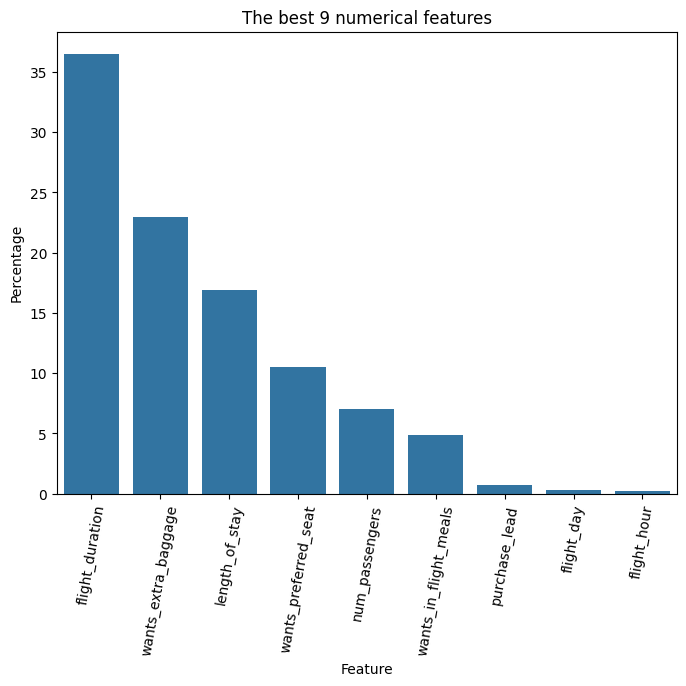

In [12]:
# Create a DataFrame to display the results
result_df = pd.DataFrame({'Feature': selected_feature_names,
                          'Score': scores,
                          'P-value': p_values,
                          'Rank': feature_rank,
                          'Percentage': feature_percentage})

result_df=result_df.sort_values(by="Rank")
plt.figure(figsize=(8,6))
plt.xticks(rotation=80)
sns.barplot(result_df.head(20),x="Feature",y="Percentage")
plt.title("The best 9 numerical features")


This ranking is based on the ANOVA F-score. Features with larger scores are more strongly associated with the target, so this output helps identify the most relevant numerical variables before model building.

In [48]:
# the best 5 features:
X1_selected=list(result_df.head(5)["Feature"])
print("The best 10 numerical features are :",X1_selected)

The best 10 numerical features are : ['flight_duration', 'wants_extra_baggage', 'length_of_stay', 'wants_preferred_seat', 'num_passengers']


## 3.2 Spearman Rank Correlation

In [49]:
# calculate the rank coefficient
rank_corr=X.corrwith(Y,method='spearman')
rank_corr_abs=np.abs(rank_corr)
rank_corr_sorted = rank_corr_abs.sort_values(ascending=False)
rank_corr_sorted

flight_duration          0.093572
length_of_stay           0.084097
wants_extra_baggage      0.079850
wants_preferred_seat     0.054151
num_passengers           0.043760
wants_in_flight_meals    0.036699
purchase_lead            0.024449
flight_hour              0.014441
flight_day               0.008610
dtype: float64

In [50]:
# Select the top-k features with the highest absolute correlation coefficients
k = 5
top_features = rank_corr_sorted[:k]
# Subset the dataset with the selected features
feature_selected = X[top_features.index]
X2_selected=feature_selected .columns.tolist()
# Print the selected features
print("Selected Features:")
print(X2_selected)

Selected Features:
['flight_duration', 'length_of_stay', 'wants_extra_baggage', 'wants_preferred_seat', 'num_passengers']


The Spearman score measures how well a feature changes with the target in rank order. A high absolute value means the feature is consistently aligned with booking completion, which is useful for confirming the selection from the ANOVA step.

In [51]:
set(X2_selected).difference(X1_selected)

set()

#### the two methods gives the same results.

## 3.3 Mutual Information

In [52]:
# Calculate mutual information between each predictor and the target
mutual_info = mutual_info_classif(X, Y)


In [53]:
# Print the mutual information scores for each predictor
#for feature, score in zip(X.columns, mutual_info):
    #print(f"{feature}: {score}")

In [54]:
#the mutual information scores for each predictor
feature_score=pd.DataFrame({"Feature":X.columns,"Score":mutual_info})
top5_feature_score=feature_score.sort_values(by="Score",ascending=False).head(5)
top5_feature_score

,Feature,Score
8,flight_duration,0.015747
5,wants_extra_baggage,0.006580
2,length_of_stay,0.006464
0,num_passengers,0.006374
7,wants_in_flight_meals,0.003922


Mutual information captures nonlinear dependency between each feature and the target. This output is especially valuable because it can detect useful relationships that correlation-based methods may miss.

## 3.4 ANOVA Ranking

In [ ]:
# Define the feature selector using ANOVA F-value
sf = SelectKBest(score_func=f_classif, k=6)  # select the top 6 features for comparison

# Fit the selector to the data
sf.fit(X, Y)

# Get the mask of selected features
selected_mask = sf.get_support()
selected_features = X.columns[selected_mask]

# Get the scores and p-values
scores = sf.scores_
p_values = sf.pvalues_

# Rank features by score
feature_rank = pd.Series(scores).rank(ascending=False)
feature_percentage = (scores / sum(scores)) * 100

# Put the results in a DataFrame
result_df = pd.DataFrame({
    'Feature': X.columns,
    'Score': scores,
    'P-value': p_values,
    'Rank': feature_rank,
    'Percentage': feature_percentage
})

result_df = result_df.sort_values(by='Rank', ascending=True).head(6)

print("Selected Features:", selected_features.tolist())
print(result_df)


Seleceted Features : 
 ['flight_duration', 'wants_extra_baggage', 'length_of_stay', 'wants_preferred_seat', 'num_passengers', 'wants_in_flight_meals']
                 Feature       Score       P-value  Rank  Percentage
8        flight_duration  325.812562  1.802311e-72   1.0   36.518772
5    wants_extra_baggage  204.737754  2.687988e-46   2.0   22.948075
2         length_of_stay  150.739562  1.430249e-34   3.0   16.895676
6   wants_preferred_seat   93.835090  3.679208e-22   4.0   10.517526
0         num_passengers   62.915900  2.227281e-15   5.0    7.051942
7  wants_in_flight_meals   43.029020  5.475784e-11   6.0    4.822917


In [20]:
# the top 5 selected features :
X3_selected=list(top5_feature_score["Feature"])
print ("The top 5 fearures selected by mutual information method are:",X3_selected)

The top 5 fearures selected by mutual information method are: ['flight_duration', 'wants_extra_baggage', 'length_of_stay', 'wants_preferred_seat', 'num_passengers']


In [21]:
set(X3_selected).difference(X2_selected)

set()

#### <p> as a final decision, we will select the features listed in the **X1_selected** list.

# 4. Select the Best Categorical Features

## 3-1 ANOVA

In [22]:
data.columns

Index(['num_passengers', 'sales_channel', 'trip_type', 'purchase_lead',
       'length_of_stay', 'flight_hour', 'flight_day', 'route',
       'booking_origin', 'wants_extra_baggage', 'wants_preferred_seat',
       'wants_in_flight_meals', 'flight_duration', 'booking_complete'],
      dtype='object')

In [23]:
# define x and y
X=categorical_cols
Y=train_df[["booking_complete"]]


In [24]:
#print("Top 10 categorical features using ANOVA and OneHotEncoder :","\n",list(result_df["Feature"][:10]))

#### let's  create a function to select  the top 10 categorical variables 

In [ ]:
def feature_selector(encoder, selector, k):
    """Return the top k categorical features using a selected scoring method."""
    if encoder == "OneHotEncoder":
        onehot_encoder = OneHotEncoder()
        X_encoded = onehot_encoder.fit_transform(X)
        X_encoded_df = pd.DataFrame(
            X_encoded.toarray(),
            columns=onehot_encoder.get_feature_names_out(X.columns)
        )
    else:
        X_encoded_df = X.apply(LabelEncoder().fit_transform)

    # Define the feature selector
    sf = SelectKBest(score_func=selector, k=k)

    # Fit and rank the encoded features
    sf.fit(X_encoded_df, Y)
    selected_mask = sf.get_support()
    selected_features = X_encoded_df.columns[selected_mask]

    scores = sf.scores_
    p_values = sf.pvalues_
    feature_rank = pd.Series(scores).rank(ascending=False)
    feature_percentage = (scores / sum(scores)) * 100

    result_df = pd.DataFrame({
        'Feature': X_encoded_df.columns,
        'Score': scores,
        'P-value': p_values,
        'Rank': feature_rank,
        'Percentage': feature_percentage
    })

    result_df = result_df.sort_values(by='Rank', ascending=True).head(k)

    print("Selected Features:", selected_features.tolist())
    print(result_df)

    return result_df.copy()

* #### One Hot Encoder

In [33]:
feature_selector("OneHotEncoder",f_classif,20)

Seleceted Features : 
 ['booking_origin_Malaysia', 'booking_origin_Australia', 'route_PENTPE', 'route_ICNPEN', 'booking_origin_Indonesia', 'route_BKIICN', 'route_ICNSYD', 'route_JHBKTM', 'booking_origin_Singapore', 'route_KIXPEN', 'booking_origin_South Korea', 'route_AKLKUL', 'booking_origin_Thailand', 'route_JHBTPE', 'sales_channel_Mobile', 'sales_channel_Internet', 'route_MELTPE', 'route_ICNJHB', 'booking_origin_China', 'route_ICNLGK']


,Feature,Score,P-value,Rank,Percentage
824,booking_origin_Malaysia,1620.663471,0.000000e+00,1.0,19.890050
782,booking_origin_Australia,1413.852966,8.500417e-303,2.0,17.351910
699,route_PENTPE,425.222433,7.302871e-94,3.0,5.218662
421,route_ICNPEN,191.307344,2.199440e-43,4.0,2.347873
811,booking_origin_Indonesia,164.309724,1.602397e-37,5.0,2.016537
44,route_BKIICN,82.161765,1.323605e-19,6.0,1.008353
430,route_ICNSYD,80.214948,3.535934e-19,7.0,0.984461
458,route_JHBKTM,79.557500,4.927778e-19,8.0,0.976392
850,booking_origin_Singapore,79.322618,5.548221e-19,9.0,0.973509
528,route_KIXPEN,78.319619,9.206736e-19,10.0,0.961200


This result applies one-hot encoding to the categorical features and ranks them using ANOVA. The selected variables are the strongest categorical predictors under this encoding approach.

* #### Label Encoder

In [34]:
feature_selector("LabelEncoder",f_classif,4)

Seleceted Features : 
 ['booking_origin', 'sales_channel', 'trip_type', 'route']


,Feature,Score,P-value,Rank,Percentage
3,booking_origin,494.196655,0.000000e+00,1.0,85.313789
0,sales_channel,60.267048,8.529014e-15,2.0,10.403976
1,trip_type,23.141253,1.512130e-06,3.0,3.994904
2,route,1.664386,1.970215e-01,4.0,0.287325


### 4.1 Chi-Square Test

* #### One Hot Encoder

In [35]:
feature_selector("OneHotEncoder",chi2,20)

Seleceted Features : 
 ['booking_origin_Malaysia', 'booking_origin_Australia', 'route_PENTPE', 'route_ICNPEN', 'booking_origin_Indonesia', 'route_BKIICN', 'route_JHBKTM', 'route_ICNSYD', 'route_KIXPEN', 'booking_origin_Singapore', 'route_AKLKUL', 'booking_origin_South Korea', 'booking_origin_Thailand', 'route_JHBTPE', 'route_MELTPE', 'sales_channel_Mobile', 'route_ICNJHB', 'route_ICNLGK', 'route_ICNKCH', 'route_LGKTPE']


,Feature,Score,P-value,Rank,Percentage
824,booking_origin_Malaysia,1325.373492,3.461360e-290,1.0,18.448073
782,booking_origin_Australia,899.574284,1.214413e-197,2.0,12.521310
699,route_PENTPE,410.568103,2.757180e-91,3.0,5.714759
421,route_ICNPEN,188.897579,5.533110e-43,4.0,2.629294
811,booking_origin_Indonesia,155.813504,9.298675e-36,5.0,2.168792
44,route_BKIICN,81.547476,1.711015e-19,6.0,1.135072
458,route_JHBKTM,78.874595,6.618037e-19,7.0,1.097867
430,route_ICNSYD,78.852675,6.691876e-19,8.0,1.097562
528,route_KIXPEN,77.760536,1.163211e-18,9.0,1.082361
850,booking_origin_Singapore,77.139445,1.593038e-18,10.0,1.073716


* #### Label Encoder

In [29]:
feature_selector("LabelEncoder",chi2,4)

Seleceted Features : 
 ['sales_channel', 'trip_type', 'route', 'booking_origin']


,Feature,Score,P-value,Rank,Percentage
3,booking_origin,12311.904566,0.000000e+00,1.0,97.966764
2,route,202.340506,6.443111e-46,2.0,1.610039
0,sales_channel,53.007954,3.322004e-13,3.0,0.421788
1,trip_type,0.177099,6.738783e-01,4.0,0.001409


### 4.2 Mutual Information

* #### One Hot Encoder

In [30]:
feature_selector("OneHotEncoder",mutual_info_classif,20)

Seleceted Features : 
 ['sales_channel_Internet', 'trip_type_RoundTrip', 'route_BDOWUH', 'route_CCUPER', 'route_COKMEL', 'route_DADMEL', 'route_DMKICN', 'route_HDYXIY', 'route_HNDKBR', 'route_ICNKBV', 'route_JHBKIX', 'route_KHHMEL', 'route_MELSUB', 'route_PENTPE', 'route_PERPUS', 'route_SUBTPE', 'booking_origin_Australia', 'booking_origin_Bahrain', 'booking_origin_Hong Kong', 'booking_origin_Malaysia']


,Feature,Score,P-value,Rank,Percentage
782,booking_origin_Australia,0.024811,None,1.0,3.204638
824,booking_origin_Malaysia,0.018582,None,2.0,2.400091
699,route_PENTPE,0.008526,None,3.0,1.101226
0,sales_channel_Internet,0.007784,None,4.0,1.005367
277,route_DMKICN,0.005861,None,5.0,0.756995
410,route_ICNKBV,0.005149,None,6.0,0.665045
619,route_MELSUB,0.004930,None,7.0,0.636728
4,trip_type_RoundTrip,0.004900,None,8.0,0.632904
378,route_HNDKBR,0.004785,None,9.0,0.618093
784,booking_origin_Bahrain,0.004745,None,10.0,0.612847


This final categorical ranking compares the variables using mutual information after encoding. It helps confirm whether the shortlisted category-based features remain informative when the relationship is not purely linear.

# 5. Final Recommendation

The feature selection results suggest that the most useful predictors are:

- Numerical features:
  - `flight_duration`
  - `wants_extra_baggage`
  - `length_of_stay`
  - `wants_preferred_seat`
  - `num_passengers`

- Categorical features:
  - `booking_origin`
  - `route`

These variables were selected because they consistently rank highly across the feature-selection methods. They provide a good balance between predictive power and model simplicity.

In [1]:
# Keep only the selected features and save them for the next modeling stage
selected_cols = [
    'flight_duration',
    'wants_extra_baggage',
    'booking_origin',
    'route',
    'length_of_stay',
    'wants_preferred_seat',
    'num_passengers',
    'booking_complete'
]

new_data = data[selected_cols].copy()
print(new_data.head())
print(f"\nFinal dataset shape: {new_data.shape}")

NameError: name 'data' is not defined

In [ ]:
# Save the reduced dataset for use in later modeling notebooks
output_path = "../data/customer_booking_after_feature_selection.csv"
new_data.to_csv(output_path, index=False)
print(f"Saved reduced dataset to: {output_path}")